In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp

In [39]:
data_dirs = ["H", "m215", "m241", "smalllight", "tube", "sunlight"]
data_names = ["Hydrogen", "Mystery 215", "Mystery 241", "Incandescent", "Fluorescent", "Sunlight"]

mean_calibrated = []
mean_calibrated_err = []

j = 0

for d in data_dirs:
    data_file = 0 # data file count for mean brightness calculation
    noise_file = 0 # noise file count for mean brightness calculation
    
    brightnesses = []
    noises = []
    
    # data files
    with open(d + "/data/files.txt") as selected_data:
        files = selected_data.readlines()
        for filename in files:
            i = 0 # metadata skipper
            brightnesses.append([])
            with open(d + "/data/" + filename.strip()) as f:
                for line in f: 
                    if i < 13:
                        i += 1
                        continue # skip reading metadata lines
                    (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                    brightnesses[data_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

            data_file += 1

    # noise files
    if d != "sunlight":
        with open(d + "/noise/files.txt") as selected_data:
            files = selected_data.readlines()
            for filename in files:
                i = 0 # metadata skipper
                noises.append([])
                with open(d + "/noise/" + filename.strip()) as f:
                    for line in f: 
                        if i < 13:
                            i += 1
                            continue # skip reading metadata lines
                        (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                        noises[noise_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

                noise_file += 1

    brightness_array = np.array(brightnesses)

    mean_brightness = np.mean(brightness_array, axis=0)
    mean_brightness_err = np.std(brightness_array, axis=0)

    mean_calibrated.append(mean_brightness)
    mean_calibrated_err.append(mean_brightness_err)

    if d != "sunlight":
        noise_array = np.array(noises)
        mean_noise = np.mean(noise_array, axis=0)
        mean_noise_err = np.std(noise_array, axis=0)

        mean_calibrated[j] = mean_brightness - mean_noise
        mean_calibrated_err[j] = np.sqrt(mean_brightness_err ** 2 + mean_noise_err ** 2) # error propagation
    
    j += 1
    
mean_calibrated = np.array(mean_calibrated)
mean_calibrated_err = np.array(mean_calibrated_err)
wavelength_array = np.array([i for i in range(350, 1001)])

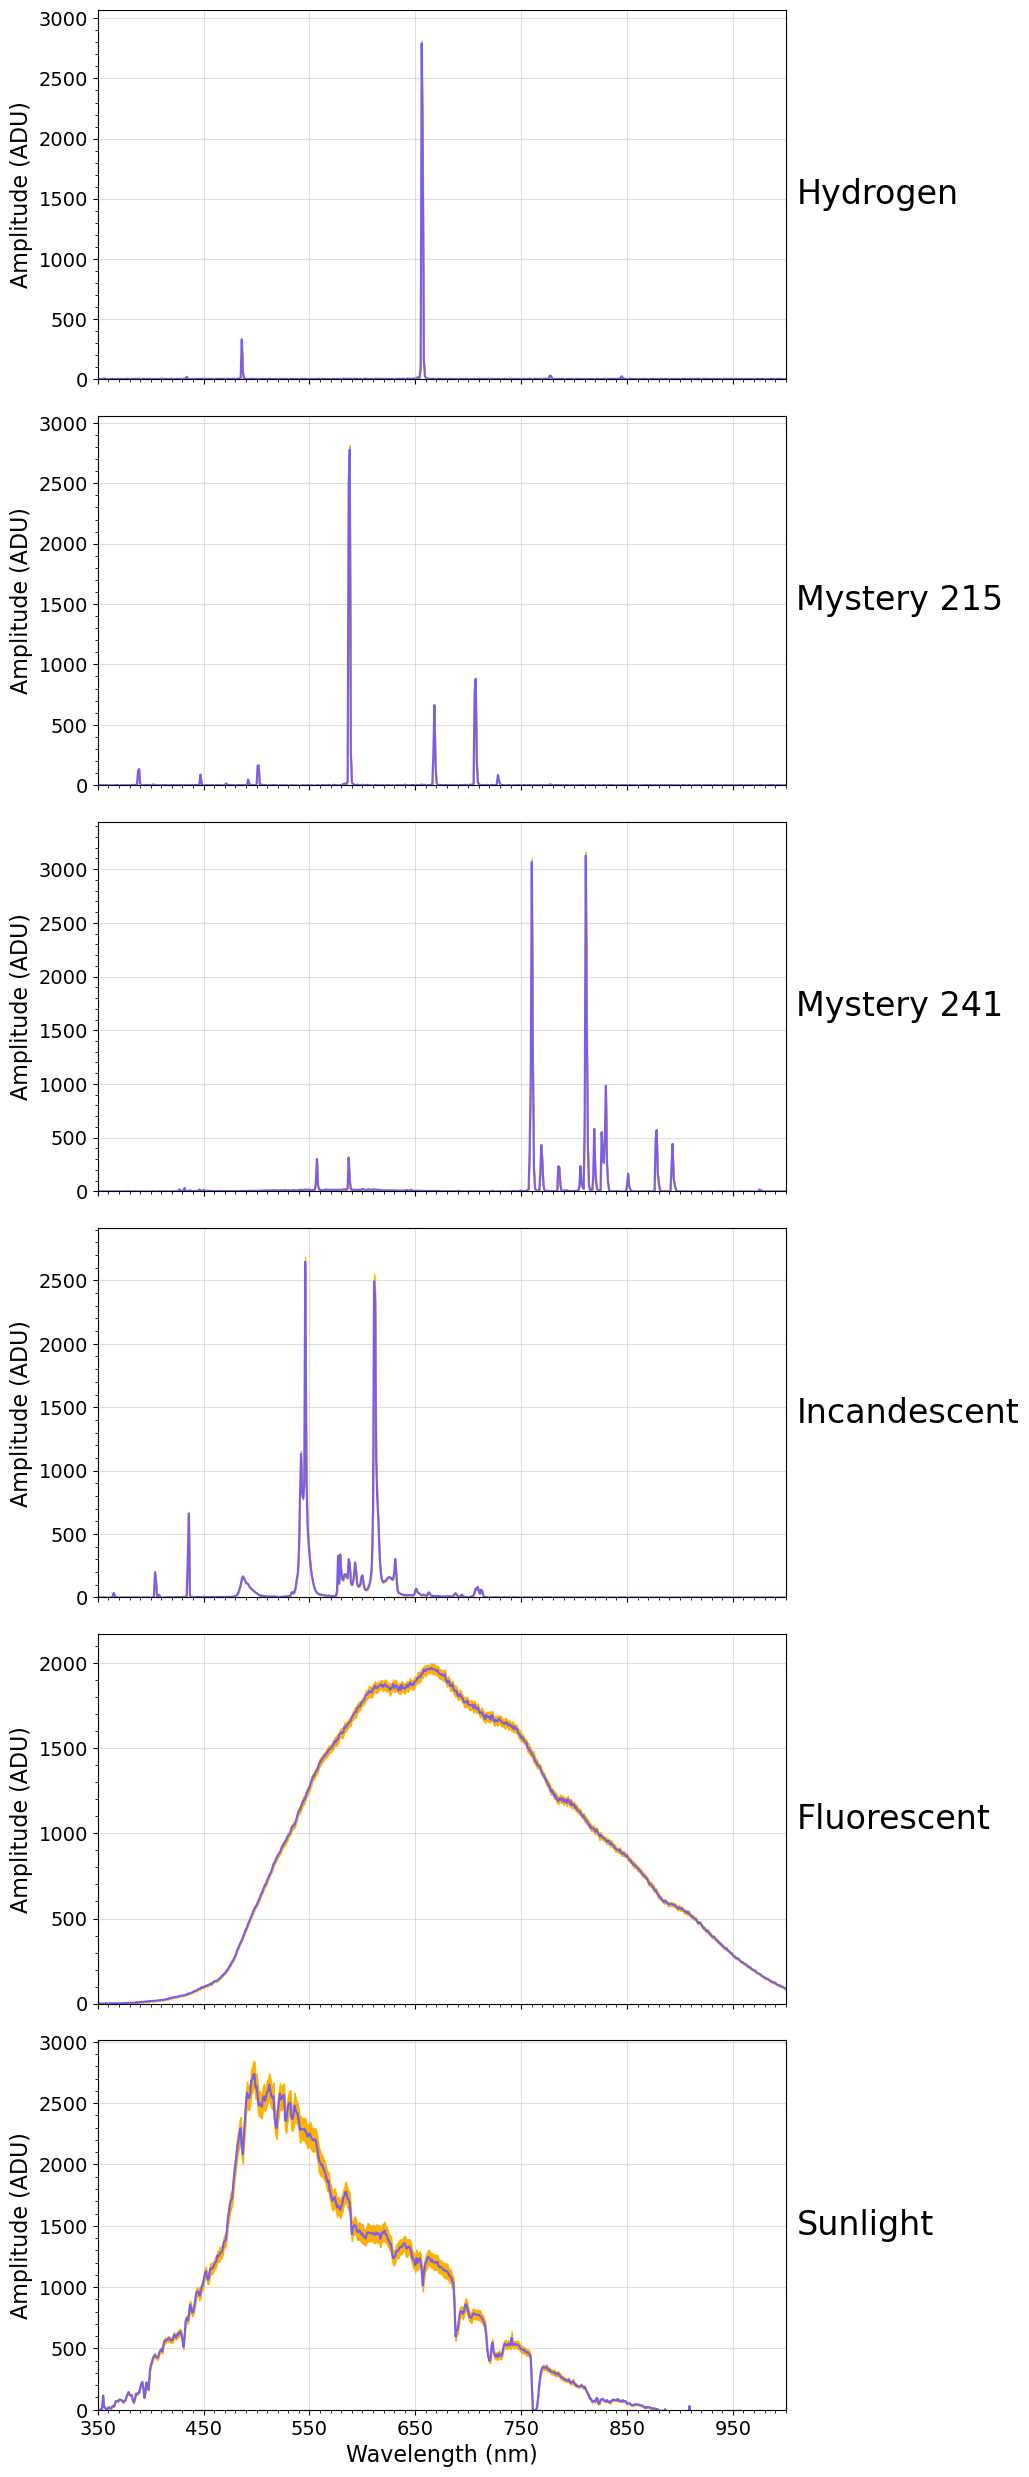

In [82]:
fig, axs = plt.subplots(6, 1, sharex=True)
plt.subplots_adjust(bottom=0, right=1.2, top=5, wspace=0.3, hspace=0.1)


for i in range(len(mean_calibrated)):
    axs[i].set_ylim(0, np.max(mean_calibrated[i])*1.1)
    axs[i].set_xlim(350, 1000)

    axs[i].set_yticks(np.arange(0, np.max(mean_calibrated[i])*1.1, 500))
    axs[i].set_yticks(np.arange(0, np.max(mean_calibrated[i])*1.1, 100), minor=True)
    axs[i].tick_params(labelsize=14)

    axs[i].set_xticks(np.arange(350, 1000, 100))
    axs[i].set_xticks(np.arange(350, 1005, 10), minor=True)

    axs[i].grid(visible=True, alpha=0.4)

    axs[i].set_ylabel("Amplitude (ADU)", fontsize=16)
    
    if i == len(mean_calibrated) - 1:
        axs[i].set_xlabel("Wavelength (nm)", fontsize=16)
    
    axs[i].text(1010, np.max(mean_calibrated[i])*1.1/2, data_names[i], va='center', fontsize=24) # right-anchored title

    axs[i].fill_between(wavelength_array, 
                    mean_calibrated[i] - mean_calibrated_err[i], 
                    mean_calibrated[i] + mean_calibrated_err[i], color='#FFB000')
    axs[i].plot(wavelength_array, mean_calibrated[i], color='#785EF0')